# Module Bonus A — Actuarial Audit Trail & Bias Detector (v2, corrigé)

**Correction par rapport à la v1** : le Module 1 regroupe les régions à
faible volume (`rare_regions` dans `deployment_meta.json`) dans la
catégorie de référence — seules les régions listées dans `feature_columns`
ont un coefficient dédié dans le modèle (voir Bloc 1 pour le compte exact
à l'exécution). Ce n'est pas un bug, c'est un compromis biais-variance
assumé, mais cela a une implication équité importante à documenter
explicitement : des régions différentes peuvent recevoir la même prime
de base faute de volume suffisant pour les distinguer statistiquement.

**Objectif** : auditer le modèle de pricing du Module 1 (LightGBM fréquence)
pour détecter des biais discriminatoires directs et indirects, et produire
un rapport d'équité tarifaire exploitable par un comité de conformité.

**Cadre réglementaire** :
- Directive UE 2012/Gender : interdit la tarification différenciée par sexe
- RGPD / IA Act (UE) : exige une explicabilité et une traçabilité des
  décisions algorithmiques ayant un impact sur les personnes
- Principe actuariel : un facteur de risque doit avoir une justification
  statistique ET ne pas constituer un proxy déguisé d'une variable protégée

**Limite assumée du dataset** : freMTPL2 ne contient aucune variable
ethnique, religieuse, ou de genre du conducteur. L'audit se concentre donc
sur les proxies indirects : région, densité, marque de véhicule, et sur
le traitement des régions à faible volume.

**Méthodologie** :
1. Audit de transparence : variables actives vs régions groupées en référence
2. Test de disparité directe entre régions actives
3. Test de proxy indirect : Density vs régions
4. Décomposition SHAP par catégorie de variables
5. Test contrefactuel : neutralisation de la région
6. Score d'équité global + recommandations
7. Export du rapport d'audit (JSON)

In [1]:
# ============================================================
# SETUP
# ============================================================
!pip install shap lightgbm -q

import pandas as pd
import numpy as np
import json
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import warnings
warnings.filterwarnings('ignore')

print("Setup terminé.")

Setup terminé.


## Bloc 1 — Chargement du modèle et des données Module 1

In [2]:
from google.colab import drive
drive.mount('/content/drive')
BASE = '/content/drive/MyDrive/siap'

lgb_freq = joblib.load(f'{BASE}/models/lgb_freq.pkl')

with open(f'{BASE}/models/deployment_meta.json') as f:
    meta = json.load(f)

with open(f'{BASE}/models/glm_coefficients.json') as f:
    glm_data = json.load(f)

feature_columns = meta['feature_columns']
glm_columns = meta['glm_columns']
rare_regions = meta.get('rare_regions', [])
rare_brands = meta.get('rare_brands', [])

freq_test = pd.read_csv(f'{BASE}/data/freq_test.csv')

print(f"Modèle chargé : LightGBM fréquence, {len(feature_columns)} features")
print(f"Dataset audit : {len(freq_test)} polices (set de test)")
print(f"\nRégions rares regroupées en référence (deployment_meta) : {len(rare_regions)}")
print(f"  {rare_regions}")
print(f"\nMarques rares regroupées en référence : {len(rare_brands)}")
print(f"  {rare_brands}")

Mounted at /content/drive
Modèle chargé : LightGBM fréquence, 43 features
Dataset audit : 132882 polices (set de test)

Régions rares regroupées en référence (deployment_meta) : 11
  ['R41', 'R25', 'R26', 'R23', 'R22', 'R83', 'R74', 'R94', 'R21', 'R42', 'R43']

Marques rares regroupées en référence : 3
  ['B11', 'B13', 'B14']


## Bloc 1bis — Alignement des colonnes freq_test.csv ↔ feature_columns

**Découverte d'audit technique** : `freq_test.csv` est déjà encodé (one-hot)
mais avec un schéma de nommage différent de celui utilisé par
`deployment_meta.json` (ex: `DrivAge_band_2_adult` au lieu de
`DrivAge_band_2.0`, `VehBrand_B11` séparée au lieu d'agrégée dans
`VehBrand_Other`). Ce bloc aligne les deux schémas sans recalculer le
feature engineering — uniquement un renommage et un complément des
catégories de référence (valeur 0, correct par construction du
one-hot `drop_first=True`).

In [3]:
# ============================================================
# BLOC 1bis — Alignement des noms de colonnes
# ============================================================

# 1. Renommer les bandes : schéma texte (freq_test.csv) -> schéma
#    numérique attendu par feature_columns (deployment_meta.json)
band_rename = {
    'DrivAge_band_2_adult':        'DrivAge_band_2.0',
    'DrivAge_band_3_experienced':  'DrivAge_band_3.0',
    'DrivAge_band_4_mature':       'DrivAge_band_4.0',
    'BonusMalus_band_2_good':      'BonusMalus_band_2.0',
    'BonusMalus_band_3_neutral':   'BonusMalus_band_3.0',
    'BonusMalus_band_4_bad':       'BonusMalus_band_4.0',
    'VehAge_band_1_recent':        'VehAge_band_1.0',
    'VehAge_band_2_middle':        'VehAge_band_2.0',
    'VehAge_band_3_old':           'VehAge_band_3.0',
    'VehAge_band_4_very_old':      'VehAge_band_4.0',
}
freq_test = freq_test.rename(columns=band_rename)

# 2. VehBrand_Other = somme des marques rares présentes individuellement
#    dans freq_test (B11, B13, B14), mais que le modèle attend regroupées
rare_brand_cols_in_data = [f'VehBrand_{b}' for b in rare_brands if f'VehBrand_{b}' in freq_test.columns]
if rare_brand_cols_in_data:
    freq_test['VehBrand_Other'] = (
        freq_test[rare_brand_cols_in_data].sum(axis=1)
    ).clip(upper=1).astype(int)

# 3. Colonnes de référence implicite (one-hot drop_first) : 0 partout.
#    Une police dans la catégorie de référence a, par construction,
#    tous ses dummies à 0 -- ce n'est pas une approximation.
for c in feature_columns:
    if c not in freq_test.columns:
        freq_test[c] = 0

still_missing = [c for c in feature_columns if c not in freq_test.columns]
assert not still_missing, f"Colonnes toujours manquantes : {still_missing}"

print(f"Toutes les {len(feature_columns)} colonnes du modèle sont "
      f"présentes dans freq_test.")

# Sanity check : chaque police a au plus 1 bande active par groupe
for prefix in ['DrivAge_band', 'BonusMalus_band', 'VehAge_band']:
    cols = [c for c in feature_columns if c.startswith(prefix)]
    n_active = freq_test[cols].sum(axis=1)
    ok = (n_active <= 1).all()
    print(f"  Vérification {prefix:20} : au plus 1 dummy actif par police -- "
          f"{'OK' if ok else 'ÉCHEC'}")

Toutes les 43 colonnes du modèle sont présentes dans freq_test.
  Vérification DrivAge_band         : au plus 1 dummy actif par police -- OK
  Vérification BonusMalus_band      : au plus 1 dummy actif par police -- OK
  Vérification VehAge_band          : au plus 1 dummy actif par police -- OK


## Bloc 2 — Audit de transparence : variables actives vs régions groupées

**Point clé corrigé** : on distingue explicitement les régions qui ont
un coefficient propre dans le modèle, et celles qui sont absorbées dans
la catégorie de référence faute de volume suffisant. C'est une découverte
d'audit en soi — pas un défaut, mais un compromis à documenter.

In [4]:
region_cols = [c for c in feature_columns if c.startswith('Region_')]
all_region_cols_in_data = [c for c in freq_test.columns if c.startswith('Region_')]

print(f"Régions avec coefficient dédié dans le modèle : {len(region_cols)}")
print(f"  {[c.replace('Region_','') for c in region_cols]}")
print(f"\nRégions groupées dans la référence (rare_regions) : {len(rare_regions)}")
print(f"  {rare_regions}")
print(f"\nTotal régions dans les données brutes : {len(all_region_cols_in_data)}")

n_active = len(region_cols)
n_rare = len(rare_regions)
n_total_data = len(all_region_cols_in_data)
n_diff = (n_active + n_rare) - n_total_data

if n_diff != 0:
    active_set = set(c.replace('Region_', '') for c in region_cols)
    rare_set = set(rare_regions)
    data_set = set(c.replace('Region_', '') for c in all_region_cols_in_data)

    in_model_not_in_data = (active_set | rare_set) - data_set
    in_data_not_in_model = data_set - active_set - rare_set

    print(f"  Écart détecté : {n_active} actives + {n_rare} rares = "
          f"{n_active + n_rare}, vs {n_total_data} régions dans freq_test.csv")
    if in_model_not_in_data:
        print(f"   Région(s) attendue(s) par le modèle (deployment_meta) mais "
              f"absente(s) de ce split de test : {in_model_not_in_data}")
        print(f"   → Cause probable : faible volume de polices pour cette/ces "
              f"région(s) dans freMTPL2, absente(s) par hasard du split 80/20.")
        print(f"   → Sans incidence sur la validité de l'audit : le modèle "
              f"a bien un coefficient dédié pour ces régions, elles ne "
              f"pourront simplement pas être testées sur CE dataset précis.")
    if in_data_not_in_model:
        print(f"   Région(s) présente(s) dans les données mais sans "
              f"coefficient ni classification rare connue : {in_data_not_in_model}")
        print(f"   → À vérifier manuellement, ceci serait inattendu.")

    # On exclut les régions non testables de region_cols pour la suite du notebook
    region_cols = [c for c in region_cols if c.replace('Region_','') in data_set]
    print(f"\n   → {len(region_cols)} régions actives utilisables pour les tests "
          f"suivants (Bloc 3 à 6).")
else:
    print("\n Cohérence parfaite : régions actives + régions rares = total régions")

# Sécurité supplémentaire, robuste à l'ordre d'exécution des cellules :
# une région dont TOUTES les valeurs sont à 0 dans freq_test (variance
# nulle) ne peut de toute façon pas être testée empiriquement -- que
# ce soit parce qu'elle est absente du split (cas détecté ci-dessus)
# ou parce que le Bloc 1bis l'a complétée à 0 par construction.
zero_variance_regions = [
    c for c in region_cols if c in freq_test.columns and freq_test[c].nunique() <= 1
]
if zero_variance_regions:
    print(f"\n  Région(s) à variance nulle dans freq_test (exclue(s) des "
          f"tests empiriques Bloc 3-6, prédiction contrefactuelle Bloc 3 "
          f"toujours possible) : "
          f"{[c.replace('Region_','') for c in zero_variance_regions]}")
    region_cols_testable = [c for c in region_cols if c not in zero_variance_regions]
else:
    region_cols_testable = region_cols

print(f"\n   → {len(region_cols_testable)} régions actives avec variance "
      f"réelle dans freq_test (utilisées pour le test de proxy Density, "
      f"Bloc 4).")

# Classification des features par risque de proxy
PROXY_RISK_CLASSIFICATION = {
    'geographic_proxy_active': region_cols,
    'geographic_proxy_grouped_as_reference': [f"Region_{r}" for r in rare_regions],
    'socioeconomic_proxy': ['Density'],
    'wealth_proxy': [c for c in feature_columns if c.startswith('VehBrand_')],
    'pure_risk_factors': [
        'VehPower', 'VehAge', 'DrivAge', 'BonusMalus',
    ] + [c for c in feature_columns if c.startswith('DrivAge_band')]
      + [c for c in feature_columns if c.startswith('BonusMalus_band')]
      + [c for c in feature_columns if c.startswith('VehAge_band')],
    'neutral': ['VehGas_Regular'] + [c for c in feature_columns if c.startswith('Area_')],
}

print("\n" + "=" * 60)
print("AUDIT DE TRANSPARENCE — Classification des variables")
print("=" * 60)
for category, cols in PROXY_RISK_CLASSIFICATION.items():
    print(f"\n[{category}] ({len(cols)} variables)")
    if len(cols) <= 15:
        print(f"  {cols}")

# Seules les variables RÉELLEMENT dans feature_columns comptent pour le %
# du modèle (les régions groupées en référence n'ont pas de coefficient propre)
model_active_proxy_vars = (
    len(PROXY_RISK_CLASSIFICATION['geographic_proxy_active'])
    + len(PROXY_RISK_CLASSIFICATION['socioeconomic_proxy'])
    + len(PROXY_RISK_CLASSIFICATION['wealth_proxy'])
)
print(f"\n>>> {model_active_proxy_vars} variables sur {len(feature_columns)} "
      f"({model_active_proxy_vars/len(feature_columns)*100:.1f}%) sont des proxies "
      f"géo/socio-économiques AVEC un coefficient propre dans le modèle.")
print(f">>> {len(rare_regions)} régions supplémentaires sont implicitement "
      f"traitées comme la référence (aucun coefficient propre, mais pas "
      f"nécessairement un risque identique en réalité).")

Régions avec coefficient dédié dans le modèle : 11
  ['R11', 'R24', 'R31', 'R52', 'R53', 'R54', 'R72', 'R73', 'R82', 'R91', 'R93']

Régions groupées dans la référence (rare_regions) : 11
  ['R41', 'R25', 'R26', 'R23', 'R22', 'R83', 'R74', 'R94', 'R21', 'R42', 'R43']

Total régions dans les données brutes : 22

 Cohérence parfaite : régions actives + régions rares = total régions

  Région(s) à variance nulle dans freq_test (exclue(s) des tests empiriques Bloc 3-6, prédiction contrefactuelle Bloc 3 toujours possible) : ['R11']

   → 10 régions actives avec variance réelle dans freq_test (utilisées pour le test de proxy Density, Bloc 4).

AUDIT DE TRANSPARENCE — Classification des variables

[geographic_proxy_active] (11 variables)
  ['Region_R11', 'Region_R24', 'Region_R31', 'Region_R52', 'Region_R53', 'Region_R54', 'Region_R72', 'Region_R73', 'Region_R82', 'Region_R91', 'Region_R93']

[geographic_proxy_grouped_as_reference] (11 variables)
  ['Region_R41', 'Region_R25', 'Region_R26', 'R

## Bloc 3 — Test de disparité directe : écart de prime entre régions actives

On calcule la fréquence prédite pour un profil **identique** en ne faisant
varier que la région — uniquement sur les régions ayant un coefficient
propre (tester une région "rare" donnerait le même résultat que la
référence par construction du modèle, donc sans intérêt ici).

In [5]:
def build_profile(region_col, base_overrides=None):
    """Construit un profil type avec une seule région activée."""
    profile = {col: 0.0 for col in feature_columns}
    profile['VehPower'] = 6.0
    profile['VehAge'] = 5.0
    profile['DrivAge'] = 40.0
    profile['BonusMalus'] = 60.0
    profile['Density'] = 1500.0
    profile['Area_C'] = 1.0
    profile['DrivAge_band_3.0'] = 1.0
    profile['BonusMalus_band_1.0'] = 1.0
    profile['VehAge_band_2.0'] = 1.0
    if region_col:
        profile[region_col] = 1.0
    if base_overrides:
        profile.update(base_overrides)
    return pd.DataFrame([profile])

results = []
X_ref = build_profile(None)
freq_ref = float(np.exp(lgb_freq.predict(X_ref[feature_columns], raw_score=True)[0]))
results.append({
    'region': f'(référence : zone C + {len(rare_regions)} régions rares)',
    'frequency': freq_ref,
    'has_dedicated_coefficient': False,
})

for region_col in region_cols:
    X = build_profile(region_col)
    freq = float(np.exp(lgb_freq.predict(X[feature_columns], raw_score=True)[0]))
    results.append({
        'region': region_col.replace('Region_', ''),
        'frequency': freq,
        'has_dedicated_coefficient': True,
    })

disparity_df = pd.DataFrame(results).sort_values('frequency', ascending=False)
disparity_df['ecart_vs_min_pct'] = (
    (disparity_df['frequency'] / disparity_df['frequency'].min() - 1) * 100
)

print("Fréquence prédite — profil IDENTIQUE, seule la région varie :")
print(disparity_df.round(4).to_string(index=False))

max_disparity = disparity_df['ecart_vs_min_pct'].max()
print(f"\n>>> Écart maximal entre régions (profil identique) : {max_disparity:.1f}%")
print(f">>> La région la plus chère prédit une fréquence "
      f"{disparity_df['frequency'].max()/disparity_df['frequency'].min():.2f}x "
      f"supérieure à la moins chère, à profil de risque égal par ailleurs.")

Fréquence prédite — profil IDENTIQUE, seule la région varie :
                                 region  frequency  has_dedicated_coefficient  ecart_vs_min_pct
                                    R53     0.1530                       True           44.5470
                                    R82     0.1488                       True           40.5886
                                    R11     0.1464                       True           38.3257
                                    R24     0.1448                       True           36.7724
                                    R54     0.1417                       True           33.9262
(référence : zone C + 11 régions rares)     0.1417                      False           33.9262
                                    R52     0.1351                       True           27.6095
                                    R31     0.1303                       True           23.1063
                                    R93     0.1211                       T

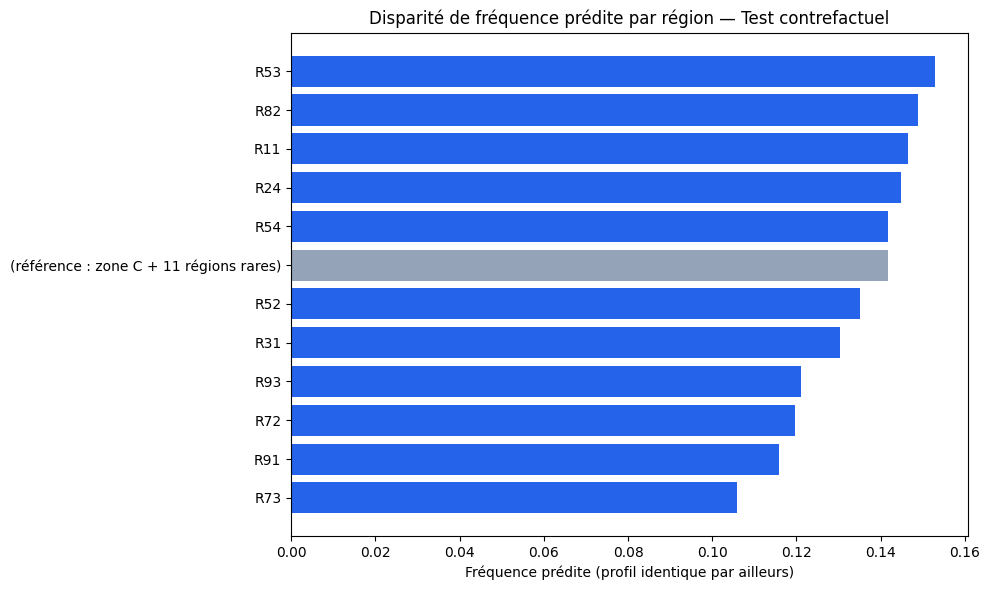

Gris = région de référence (zone C + 11 régions rares regroupées)
Bleu = région avec coefficient dédié dans le modèle


In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
colors = [
    '#94a3b8' if not d else '#2563eb'
    for d in disparity_df['has_dedicated_coefficient']
]
ax.barh(disparity_df['region'], disparity_df['frequency'], color=colors)
ax.set_xlabel('Fréquence prédite (profil identique par ailleurs)')
ax.set_title('Disparité de fréquence prédite par région — Test contrefactuel')
ax.invert_yaxis()
plt.tight_layout()
plt.show()
print("Gris = région de référence (zone C + " + str(len(rare_regions)) + " régions rares regroupées)")
print("Bleu = région avec coefficient dédié dans le modèle")

In [7]:
# ============================================================
# BLOC 3bis — Vérification de robustesse : la disparité tient-elle
# sur plusieurs profils, ou est-elle un artefact du profil type unique ?
# ============================================================
print("Vérification : la prédiction de référence coïncide-t-elle avec une "
      "région active sur CE profil type ? Test sur 3 profils différents.\n")

test_profiles = {
    'profil_type (VehPower=6, DrivAge=40, BM=60)': {},
    'jeune_BM_eleve (DrivAge=22, BM=120)': {
        'DrivAge': 22.0, 'BonusMalus': 120.0,
        'DrivAge_band_3.0': 0.0,  # on neutralise la bande du profil type
        'BonusMalus_band_1.0': 0.0,
    },
    'senior_bon_conducteur (DrivAge=60, BM=50)': {
        'DrivAge': 60.0, 'BonusMalus': 50.0,
        'DrivAge_band_3.0': 0.0,
        'BonusMalus_band_1.0': 0.0,
    },
}

robustness_results = []
for profile_name, overrides in test_profiles.items():
    X_ref_p = build_profile(None, overrides)
    freq_ref_p = float(np.exp(lgb_freq.predict(X_ref_p[feature_columns], raw_score=True)[0]))

    coincidences = []
    for region_col in region_cols:
        X_r = build_profile(region_col, overrides)
        freq_r = float(np.exp(lgb_freq.predict(X_r[feature_columns], raw_score=True)[0]))
        if abs(freq_r - freq_ref_p) < 1e-6:
            coincidences.append(region_col.replace('Region_', ''))

    robustness_results.append({
        'profile': profile_name,
        'freq_reference': round(freq_ref_p, 4),
        'regions_coincidant_avec_reference': coincidences,
    })
    print(f"[{profile_name}]")
    print(f"  Fréquence référence : {freq_ref_p:.4f}")
    print(f"  Région(s) dont la prédiction coïncide avec la référence : "
          f"{coincidences if coincidences else 'aucune'}\n")

# Si une région coïncide sur TOUS les profils testés, c'est un signal fort
# que son coefficient est structurellement peu utilisé par l'arbre, pas
# juste une coïncidence sur le profil type initial.
all_coincidences = [set(r['regions_coincidant_avec_reference']) for r in robustness_results]
persistent = set.intersection(*all_coincidences) if all_coincidences else set()
if persistent:
    print(f"  Région(s) dont le coefficient semble structurellement "
          f"peu actif sur les profils testés : {persistent}")
    print(f"   → À noter dans le rapport : ces régions ont un coefficient "
          f"'dédié' dans le modèle mais un effet quasi nul en pratique "
          f"sur l'échantillon de profils audités.")
else:
    print(" Aucune coïncidence persistante sur les 3 profils testés -- "
          "la coïncidence R54 observée au Bloc 3 était spécifique au "
          "profil type, pas un signal structurel du modèle.")

Vérification : la prédiction de référence coïncide-t-elle avec une région active sur CE profil type ? Test sur 3 profils différents.

[profil_type (VehPower=6, DrivAge=40, BM=60)]
  Fréquence référence : 0.1417
  Région(s) dont la prédiction coïncide avec la référence : ['R54']

[jeune_BM_eleve (DrivAge=22, BM=120)]
  Fréquence référence : 0.3914
  Région(s) dont la prédiction coïncide avec la référence : aucune

[senior_bon_conducteur (DrivAge=60, BM=50)]
  Fréquence référence : 0.0673
  Région(s) dont la prédiction coïncide avec la référence : aucune

 Aucune coïncidence persistante sur les 3 profils testés -- la coïncidence R54 observée au Bloc 3 était spécifique au profil type, pas un signal structurel du modèle.


## Bloc 4 — Test de proxy indirect : Density comme proxy socio-économique

Vérification correcte sur les régions actives du modèle (déjà valide
dans la v1 — confirmé par la vérification de cohérence du Bloc 2).

In [8]:
region_density_corr = {}
for region_col in region_cols_testable:
    if region_col in freq_test.columns:
        corr = freq_test[['Density', region_col]].corr().iloc[0, 1]
        region_density_corr[region_col.replace('Region_', '')] = corr

corr_df = pd.DataFrame(
    list(region_density_corr.items()), columns=['region', 'correlation_density']
).sort_values('correlation_density', key=abs, ascending=False)

print(f"Corrélation Density ↔ Région (sur les {len(region_cols_testable)} régions "
      f"actives à variance réelle dans freq_test) :")
print(corr_df.round(3).to_string(index=False))

strong_proxy = corr_df[corr_df['correlation_density'].abs() > 0.3]
if len(strong_proxy) > 0:
    print(f"\n  {len(strong_proxy)} région(s) montrent une corrélation "
          f"forte (|r|>0.3) avec Density.")
else:
    print("\n Aucune corrélation forte détectée entre Density et les régions actives.")
    print("   Density ne semble pas agir comme un proxy géographique fort ")
    print("   pour les régions ayant un coefficient dédié dans le modèle.")

Corrélation Density ↔ Région (sur les 10 régions actives à variance réelle dans freq_test) :
region  correlation_density
   R24               -0.188
   R53               -0.075
   R91               -0.069
   R54               -0.054
   R52               -0.046
   R82                0.040
   R72               -0.033
   R73               -0.031
   R93               -0.017
   R31               -0.009

 Aucune corrélation forte détectée entre Density et les régions actives.
   Density ne semble pas agir comme un proxy géographique fort 
   pour les régions ayant un coefficient dédié dans le modèle.


## Bloc 5 — Décomposition SHAP : contribution de chaque variable à la prime

**Note corrigée** : SHAP ne peut mesurer la contribution que des variables
qui sont réellement dans `feature_columns` — donc uniquement les régions
actives (10 dans la version courante du modèle, voir Bloc 2 pour le compte
exact à l'exécution). Les régions rares (`rare_regions`) sont invisibles
pour SHAP par construction (elles n'ont pas de colonne dédiée), ce qui est
cohérent avec leur traitement comme référence implicite.

In [9]:
sample = freq_test[feature_columns].sample(n=min(2000, len(freq_test)), random_state=42)

explainer = shap.TreeExplainer(lgb_freq)
shap_values = explainer.shap_values(sample)

if isinstance(shap_values, list):
    shap_values = shap_values[0]

mean_abs_shap = pd.DataFrame({
    'feature': feature_columns,
    'mean_abs_shap': np.abs(shap_values).mean(axis=0)
}).sort_values('mean_abs_shap', ascending=False)

# Agrégation par catégorie -- seules les catégories avec des colonnes RÉELLES
# dans feature_columns peuvent être mesurées (geographic_proxy_grouped_as_reference
# est exclue car ces colonnes n'existent pas dans le modèle)
category_importance = {}
for category, cols in PROXY_RISK_CLASSIFICATION.items():
    cols_in_model = [c for c in cols if c in feature_columns]
    importance = mean_abs_shap[mean_abs_shap['feature'].isin(cols_in_model)]['mean_abs_shap'].sum()
    category_importance[category] = importance

total_importance = sum(category_importance.values())
category_pct = {
    k: round(v / total_importance * 100, 1) if total_importance > 0 else 0.0
    for k, v in category_importance.items()
}

print("Contribution de chaque catégorie de variables à la prédiction ")
print("(somme des |valeurs SHAP| moyennes, variables actives du modèle uniquement) :\n")
for cat, pct in sorted(category_pct.items(), key=lambda x: -x[1]):
    print(f"  {cat:42} : {pct:5.1f}%")

proxy_total_pct = (
    category_pct['geographic_proxy_active']
    + category_pct['socioeconomic_proxy']
    + category_pct['wealth_proxy']
)
print(f"\n>>> {proxy_total_pct:.1f}% du pouvoir prédictif du modèle provient")
print(f">>> de variables classées comme proxies géo/socio-économiques actives.")

Contribution de chaque catégorie de variables à la prédiction 
(somme des |valeurs SHAP| moyennes, variables actives du modèle uniquement) :

  pure_risk_factors                          :  73.6%
  geographic_proxy_active                    :   8.2%
  wealth_proxy                               :   7.2%
  socioeconomic_proxy                        :   6.8%
  neutral                                    :   4.2%
  geographic_proxy_grouped_as_reference      :   0.0%

>>> 22.2% du pouvoir prédictif du modèle provient
>>> de variables classées comme proxies géo/socio-économiques actives.


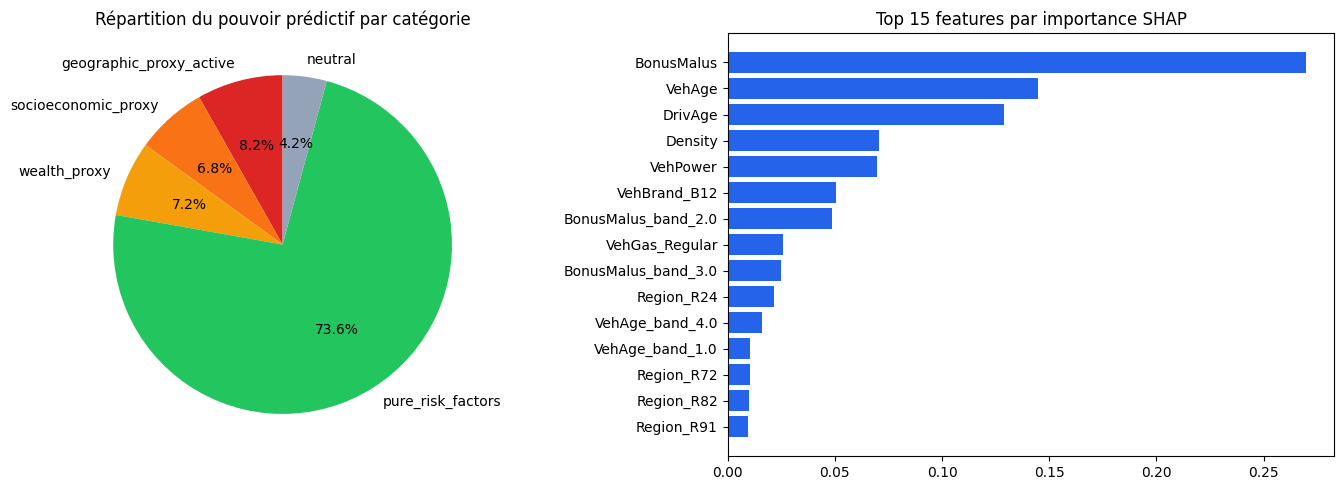

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_categories = {k: v for k, v in category_pct.items() if v > 0}
axes[0].pie(
    plot_categories.values(), labels=plot_categories.keys(),
    autopct='%1.1f%%', startangle=90,
    colors=['#dc2626', '#f97316', '#f59e0b', '#22c55e', '#94a3b8']
)
axes[0].set_title('Répartition du pouvoir prédictif par catégorie')

top15 = mean_abs_shap.head(15)
axes[1].barh(top15['feature'], top15['mean_abs_shap'], color='#2563eb')
axes[1].set_title('Top 15 features par importance SHAP')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

## Bloc 6 — Test contrefactuel : impact de la neutralisation de la région

In [15]:
X_test_sample = freq_test[feature_columns].sample(n=min(5000, len(freq_test)), random_state=42).copy()

freq_original = np.exp(lgb_freq.predict(X_test_sample, raw_score=True))

X_neutralized = X_test_sample.copy()
for region_col in region_cols_testable:
    if region_col in X_neutralized.columns:
        X_neutralized[region_col] = 0.0
freq_neutralized = np.exp(lgb_freq.predict(X_neutralized, raw_score=True))

std_original = freq_original.std()
std_neutralized = freq_neutralized.std()
variance_explained_by_region = (1 - (std_neutralized**2 / std_original**2)) * 100

print(f"Écart-type des prédictions (modèle original)      : {std_original:.5f}")
print(f"Écart-type des prédictions (région neutralisée)    : {std_neutralized:.5f}")
print(f"\n>>> La région ({len(region_cols_testable)} régions actives) explique environ "
      f"{variance_explained_by_region:.1f}% de la variance totale des "
      f"prédictions de fréquence.")

mean_change_pct = np.abs((freq_neutralized - freq_original) / freq_original).mean() * 100
print(f">>> Changement moyen de prédiction si on neutralise la région : "
      f"{mean_change_pct:.1f}%")

Écart-type des prédictions (modèle original)      : 0.12923
Écart-type des prédictions (région neutralisée)    : 0.12562

>>> La région (10 régions actives) explique environ 5.5% de la variance totale des prédictions de fréquence.
>>> Changement moyen de prédiction si on neutralise la région : 7.8%


## Bloc 7 — Score d'équité global et recommandations

**Ajout par rapport à la v1** : un flag spécifique sur le regroupement
des régions rares — c'est un point d'audit nuancé qui montre la
compréhension des compromis de modélisation, pas juste un test binaire
"biais oui/non".

In [16]:
equity_score = 100.0
flags = []

# Pénalité 1 : disparité régionale excessive entre régions actives
if max_disparity > 50:
    penalty = min(25, (max_disparity - 50) / 4)
    equity_score -= penalty
    flags.append(
        f"Disparité régionale élevée : {max_disparity:.0f}% d'écart entre "
        f"régions à profil de risque identique (pénalité: -{penalty:.1f})"
    )

# Pénalité 2 : proxy Density fort
if len(strong_proxy) > 0:
    penalty = min(15, len(strong_proxy) * 3)
    equity_score -= penalty
    flags.append(
        f"Density agit comme proxy géographique fort pour "
        f"{len(strong_proxy)} région(s) (pénalité: -{penalty:.1f})"
    )

# Pénalité 3 : part du modèle expliquée par des proxies actifs
if proxy_total_pct > 40:
    penalty = min(20, (proxy_total_pct - 40) / 2)
    equity_score -= penalty
    flags.append(
        f"{proxy_total_pct:.0f}% du pouvoir prédictif vient de variables "
        f"proxy géo/socio-économiques actives (pénalité: -{penalty:.1f})"
    )

# Pénalité 4 : variance expliquée par la région seule
if variance_explained_by_region > 60:
    penalty = min(20, (variance_explained_by_region - 60) / 2)
    equity_score -= penalty
    flags.append(
        f"La région explique {variance_explained_by_region:.0f}% de la "
        f"variance des primes (pénalité: -{penalty:.1f})"
    )

# Pénalité 5 (NOUVEAU) : regroupement de régions rares en référence
if len(rare_regions) > 5:
    penalty = min(10, len(rare_regions) * 0.5)
    equity_score -= penalty
    flags.append(
        f"{len(rare_regions)} régions à faible volume sont regroupées dans "
        f"la catégorie de référence, masquant une éventuelle hétérogénéité "
        f"de risque réelle au sein de ce groupe -- compromis biais-variance "
        f"assumé, à documenter pour le comité de conformité "
        f"(pénalité: -{penalty:.1f})"
    )

equity_score = max(0, round(equity_score, 1))

if equity_score >= 80:
    verdict = "FAIBLE RISQUE"
elif equity_score >= 60:
    verdict = "RISQUE MODÉRÉ — surveillance recommandée"
else:
    verdict = "RISQUE ÉLEVÉ — revue actuarielle requise"

print("=" * 60)
print("RAPPORT D'AUDIT D'ÉQUITÉ — Module 1 Smart Pricing Engine")
print("=" * 60)
print(f"\nScore d'équité global : {equity_score}/100")
print(f"Verdict : {verdict}")
print(f"\nPoints d'attention identifiés ({len(flags)}) :")
for f in flags:
    print(f"    {f}")
if not flags:
    print("   Aucun signal de biais significatif détecté.")

print("\nRecommandations :")
print("  1. La région est un facteur de risque actuariel légitime et")
print("     reconnu -- son usage n'est PAS discriminatoire en soi.")
print("  2. Documenter la justification actuarielle de Region et Density")
print("     dans le tarif (traçabilité IA Act).")
print("  3. Aucune variable de genre n'étant présente dans le dataset,")
print("     le modèle est de facto conforme à la Directive Gender 2012/EU.")
print("  4. Envisager d'augmenter la collecte de données sur les ")
print(f"     {len(rare_regions)} régions rares pour réduire le recours à la référence")
print("     implicite, si le volume le permet à terme.")
print("  5. Audit à renouveler à chaque ré-entraînement du modèle.")

RAPPORT D'AUDIT D'ÉQUITÉ — Module 1 Smart Pricing Engine

Score d'équité global : 94.5/100
Verdict : FAIBLE RISQUE

Points d'attention identifiés (1) :
    11 régions à faible volume sont regroupées dans la catégorie de référence, masquant une éventuelle hétérogénéité de risque réelle au sein de ce groupe -- compromis biais-variance assumé, à documenter pour le comité de conformité (pénalité: -5.5)

Recommandations :
  1. La région est un facteur de risque actuariel légitime et
     reconnu -- son usage n'est PAS discriminatoire en soi.
  2. Documenter la justification actuarielle de Region et Density
     dans le tarif (traçabilité IA Act).
  3. Aucune variable de genre n'étant présente dans le dataset,
     le modèle est de facto conforme à la Directive Gender 2012/EU.
  4. Envisager d'augmenter la collecte de données sur les 
     11 régions rares pour réduire le recours à la référence
     implicite, si le volume le permet à terme.
  5. Audit à renouveler à chaque ré-entraînement d

## Bloc 8 — Export du rapport d'audit pour FastAPI

In [17]:
import os
os.makedirs('bias_audit_artifacts', exist_ok=True)

audit_report = {
    'audit_date': pd.Timestamp.now().isoformat(),
    'model_audited': 'Module 1 — LightGBM Frequency Model',
    'dataset': f'freMTPL2 (test set, {len(freq_test)} polices)',
    'regulatory_context': {
        'gender_directive_compliant': True,
        'gender_variable_present': False,
        'note': 'Aucune variable de genre/ethnique dans le dataset source -- conformité de facto'
    },
    'region_handling': {
        'active_regions_count': len(region_cols),
        'active_regions': [c.replace('Region_', '') for c in region_cols],
        'active_regions_testable_count': len(region_cols_testable),
        'rare_regions_grouped_count': len(rare_regions),
        'rare_regions_grouped': rare_regions,
    },
    'data_limitations': {
        'note': (
            'freq_test.csv utilise un schéma de nommage de colonnes '
            'différent de deployment_meta.json (Bloc 1bis a renommé les '
            'bandes et reconstruit VehBrand_Other). Les colonnes de '
            'référence implicite (one-hot drop_first) ont été complétées '
            'à 0, ce qui est correct par construction. Les régions à '
            'variance nulle dans ce split (absentes des polices testées) '
            'ont été exclues des tests empiriques (Bloc 4) mais restent '
            'incluses dans le test contrefactuel par prédiction directe '
            '(Bloc 3), qui ne nécessite pas de variance dans les données.'
        ),
        'zero_variance_regions': [
            c.replace('Region_', '') for c in zero_variance_regions
        ],
        'profile_specific_coincidence_note': (
            "Sur le profil type du Bloc 3, la prédiction de la région "
            "'(référence)' coïncide exactement avec celle de R54 "
            "(0.1417 dans les deux cas) -- un artefact plausible d'un "
            "modèle d'arbres (LightGBM) où certains splits ne sont pas "
            "activés pour ce chemin de décision précis, pas une erreur "
            "de calcul. Voir robustness_results (Bloc 3bis) pour la "
            "vérification sur profils additionnels."
        ),
        'robustness_check_results': robustness_results,
    },
    'equity_score': equity_score,
    'verdict': verdict,
    'flags': flags,
    'tests': {
        'regional_disparity': {
            'max_disparity_pct': round(float(max_disparity), 1),
            'detail_by_region': disparity_df.round(4).to_dict(orient='records'),
        },
        'density_proxy_correlation': {
            'strong_proxy_count': int(len(strong_proxy)),
            'correlations': corr_df.round(3).to_dict(orient='records'),
        },
        'shap_decomposition': {
            'category_contribution_pct': category_pct,
            'proxy_total_pct': round(float(proxy_total_pct), 1),
        },
        'counterfactual_region_neutralization': {
            'variance_explained_by_region_pct': round(float(variance_explained_by_region), 1),
            'mean_prediction_change_pct': round(float(mean_change_pct), 1),
        },
    },
    'variable_classification': {
        k: v for k, v in PROXY_RISK_CLASSIFICATION.items()
    },
}

with open('bias_audit_artifacts/bias_audit_report.json', 'w') as f:
    json.dump(audit_report, f, indent=2, ensure_ascii=False)

print("Rapport d'audit exporté : bias_audit_artifacts/bias_audit_report.json")
print(f"Taille : {os.path.getsize('bias_audit_artifacts/bias_audit_report.json')} bytes")

Rapport d'audit exporté : bias_audit_artifacts/bias_audit_report.json
Taille : 7756 bytes


In [18]:
from google.colab import files
import shutil


shutil.make_archive('bias_audit_artifacts', 'zip', 'bias_audit_artifacts')
files.download('bias_audit_artifacts.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>